In [40]:
import sys
import tensorflow as tf

print("Python executable:", sys.executable)
print("TensorFlow version:", tf.__version__)
print("TensorFlow path:", tf.__file__)
print("CUDA build:", tf.test.is_built_with_cuda())
print("GPUs:", tf.config.list_physical_devices("GPU"))

Python executable: C:\Users\JOSS0001\AppData\Local\anaconda3\envs\Lab3-4\python.exe
TensorFlow version: 2.20.0
TensorFlow path: C:\Users\JOSS0001\AppData\Local\anaconda3\envs\Lab3-4\lib\site-packages\tensorflow\__init__.py
CUDA build: False
GPUs: []


In [2]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

def combine_sensorData(file1, file2, fileProcessed):
    f1 = pd.read_csv(file1)
    f2 = pd.read_csv(file2)
    
    df = pd.merge_asof(f1, f2, on="Time (s)")
        
    df.to_csv(fileProcessed)
    return df

def downsample_class(df):
    # Downsample each recording separately
    df = df.iloc[::4] # Take every 4th sample
    return df.reset_index(drop=True)

root_folder = "C:\\Users\\JOSS0001\\OneDrive - Högskolan Kristianstad\\CTerminator 2\\Lab4_prep_JovanSsettuba"

all_data = []

for root, folders, files in os.walk(root_folder):
    # Check if this folder contains both sensor files
    if "Accelerometer.csv" in files and "Gyroscope.csv" in files:

        # File paths
        accelerometer_path = os.path.join(root, "Accelerometer.csv")
        gyro_path = os.path.join(root, "Gyroscope.csv")

        # Read files
        acc = pd.read_csv(accelerometer_path)
        gyro = pd.read_csv(gyro_path)

        # Merge on time
        df = pd.merge(
            acc,
            gyro,
            on="Time (s)",
            how="inner"
        )

        # Add label and recording ID
        df.columns = ["time", "ax", "ay", "az", "gx", "gy", "gz"]
        #df["label"] = label
        #df["recording_id"] = recording_id

        # Store result
        all_data.append(df)

# Combine all recordings
final_df = pd.concat(all_data, ignore_index=True)
final_df.to_csv("combined.csv")

In [5]:
import numpy as np

# -----------------------------------------------------------
# Function to transform data into windows
# -----------------------------------------------------------

def create_windows(data, window_size, step_size):
    # Create empty lists to store the windows and their labels
    X = []
    y = []
    
    features = ["ax", "ay", "az", "gx", "gy", "gz"]

    # Group the dataset by recording_id so windows never cross recordings
    for recording_id, recording in data.groupby('recording_id'):

        # Get the sensor measurements for this recording
        sensor_data = recording[features].to_numpy()

        # Get the class label for this recording
        label = recording['label'].iloc[0]

        # Move through the recording to create windows
        for start in range(0, len(sensor_data) - window_size + 1, step_size):

            # Calculate the end position of the current window
            end = start + window_size

            # Extract the sensor measurements within this window
            window = sensor_data[start:end]

            # Add the window to the input data
            X.append(window)

            # Assign the recording's class label to this window
            y.append(label)

    # Convert the lists into NumPy arrays for machine learning
    X = np.array(X)
    y = np.array(y)

    # Return the windows and their corresponding labels
    return X, y

In [34]:
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder

# ---------------------------
# Preprocessing and prep data for GRU model
# ---------------------------

window_size = 100 #test 10, 100, 200
step_size = 10

train_data = pd.read_csv("ntrain_set.csv")
val_data = pd.read_csv("nval_set.csv")

t_features, t_activity = create_windows(train_data, window_size, step_size)
v_features, v_activity = create_windows(val_data, window_size, step_size)

label_encoder = LabelEncoder() # Create an encoder for the activity labels
t_activity = label_encoder.fit_transform(t_activity) # Convert training labels from strings to integers
v_activity = label_encoder.transform(v_activity) # Convert validation labels using the same mapping
# print(label_encoder.classes_) # Show which number represents each activity


# Print the shapes to check the results
print("X_train shape:", t_features.shape)
print("X_val shape:", v_features.shape)
#print("y_train shape:", t_activity.shape)

# ---------------------------
# Create GRU model
# ---------------------------

model = keras.Sequential([
    keras.layers.Input(shape=(window_size, 6)),
    keras.layers.GRU(100, return_sequences=True), # GRU units working together to learn patterns 10, 50, 100
    keras.layers.GRU(100), # GRU units working together to learn patterns 10, 50, 100
    keras.layers.Dense(4, activation='softmax')
])

model.compile( # Compile model first so it knows how it should learn before training
    optimizer="adam", # how weights are updated
    loss="sparse_categorical_crossentropy", # what model tries to minimize
    metrics=["accuracy"] # How many predictions are correct
)

history = model.fit( #Start the training process
    t_features,
    t_activity,
    validation_data=(v_features, v_activity),
    epochs=10,
)
#print(history.history.keys())

X_train shape: (6869, 100, 6)
X_val shape: (1714, 100, 6)
Epoch 1/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 24s 85ms/step - accuracy: 0.6810 - loss: 0.7423 - val_accuracy: 0.9994 - val_loss: 0.0139
Epoch 2/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 20s 94ms/step - accuracy: 0.9999 - loss: 0.0081 - val_accuracy: 0.9994 - val_loss: 0.0083
Epoch 3/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.9996 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 4/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 9.7447e-04
Epoch 5/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 20s 88ms/step - accuracy: 1.0000 - loss: 6.9427e-04 - val_accuracy: 1.0000 - val_loss: 6.2416e-04
Epoch 6/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - accuracy: 1.0000 - loss: 4.6336e-04 - val_accuracy: 1.0000 - val_loss: 4.3568e-04
Epoch 7/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 18s 85ms/step - accuracy: 1.0000 - loss: 3.2234e-04 - val_accuracy: 1.0000 - val_loss: 3.2188e-04
Epoc

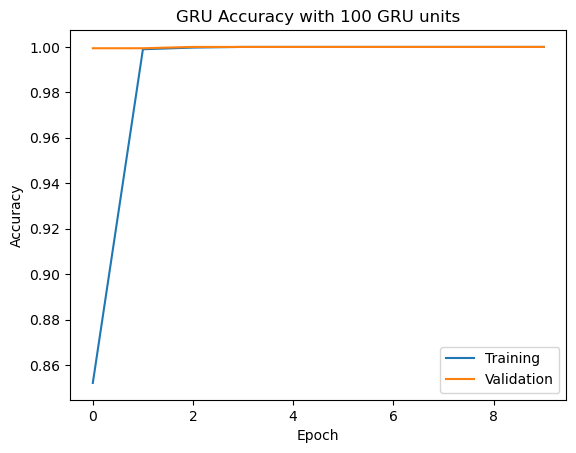

In [36]:
# ---------------------------
# Plot model accuracy
# ---------------------------

plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('GRU Accuracy with 100 GRU units')
plt.legend()
plt.show()

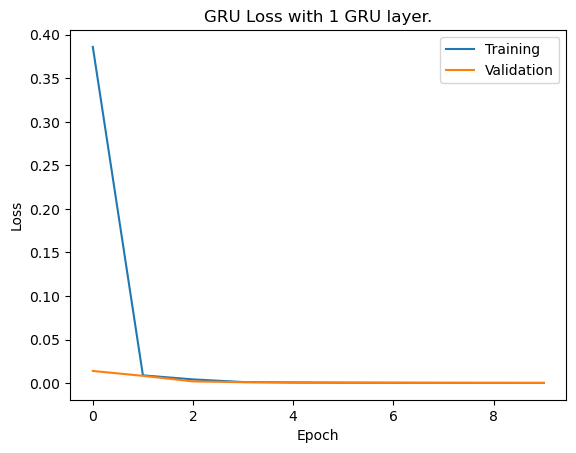

In [35]:
# ---------------------------
# Plot the loss
# ---------------------------
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GRU Loss with 1 GRU layer.')
plt.legend()
plt.show()

In [38]:
import tensorflow as tf

# Display GPUs available to TensorFlow
print(tf.config.list_physical_devices('GPU'))

[]


In [39]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("Available GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
Built with CUDA: False
Available GPUs: []
